In diesem Notebook werden die probabilistischen Goldstandards erstellt.

1. Laden der im "00_clean_event_data.iypnb" aufbereiteten Daten mit den Feldern "item", "task, "worker", "label", "title"
2. Auswahl eines Titels, für den die prob. Goldstandards erstellt werden sollen --> String anpassen
3. Crowd-Kit-Anwendung: Dawid&Skene, MACE und GLAD
4. Die probabilistischen Goldstandards werden auf den manuellen Goldstandard gematched, dieser Dataframe wird unter dem jeweiligen Subdir gespeichert z.B. '"../data/effi/261311_goldlabel_vgl.csv"' --> manuell anpassen
5. Es werden Zeilen herausgesucht, in den mind. einer der prob. GT != manueller Goldstandard
6. Es werden alle Zeilen ermittelt, wo die prob. Golstandards alle übereinstimmen, aber != manueller Goldstandard
6. Konfusionsmatrizen werden erstellt für alle Goldstandards im Vgl. (absolute Zahlen und prozentuale Verteilungen)
7. F1-Scores für den alglemeinen Vgl. der Goldstandards werden ermittelt und extra für Labelvergleich
8. Visualisierungen Konfusionsmatrizeen absolute Zahlen

In [1]:
import json
import pandas as pd
from itertools import combinations


## Read preprocessed event annotations

In [2]:
df = pd.read_csv("../data/261211_final_data.csv")

In [3]:
display(df.head(10))

,title,item,task,worker,label
0,Das Erdbeben in Chili,"als ihr schon, auf Befehl des Erzbischofs, der...",1,Annotator1,process
1,Das Erdbeben in Chili,"als ihr schon, auf Befehl des Erzbischofs, der...",1,Annotator2,process
2,Das Erdbeben in Chili,"als ihr schon, auf Befehl des Erzbischofs, der...",1,gold_standard,process
3,Das Erdbeben in Chili,Josephe antwortete,2,Annotator1,process
4,Das Erdbeben in Chili,Josephe antwortete,2,Annotator2,process
5,Das Erdbeben in Chili,Josephe antwortete,2,gold_standard,process
6,Das Erdbeben in Chili,Jeronimo wollte die Besinnung verlieren,3,Annotator1,stative_event
7,Das Erdbeben in Chili,Jeronimo wollte die Besinnung verlieren,3,Annotator2,stative_event
8,Das Erdbeben in Chili,Jeronimo wollte die Besinnung verlieren,3,gold_standard,stative_event
9,Das Erdbeben in Chili,"und sie wandte sich, um nach dem Kloster zu eilen",4,Annotator1,process


In [4]:
df[
    (df["title"] == "Der blonde Eckbert") &
    (df["task"] == 1)
][["item", "worker", "label"]]

,item,worker,label
2088,Es war ein rauher stürmischer Wintertag,Annotator1,stative_event
2089,Es war ein rauher stürmischer Wintertag,Annotator2,stative_event
2090,Es war ein rauher stürmischer Wintertag,gold_standard,stative_event


### Group by title mit Spalten "task", "anno1", "anno2" und "goldstandard" zum Vergleich der Annotationen

In [5]:
pivot_df = df.pivot_table(
    index=["title", "task"],
    columns="worker",
    values="label",
    aggfunc="first"
)

display(pivot_df)

worker                         Annotator1     Annotator2  gold_standard
title                 task                                             
Das Erdbeben in Chili 1           process        process        process
                      2           process        process        process
                      3     stative_event  stative_event  stative_event
                      4           process        process        process
                      5           process        process        process
...                                   ...            ...            ...
Krambambuli           542       non_event        process        process
                      543       non_event      non_event      non_event
                      544         process        process        process
                      545         process  stative_event  stative_event
                      546       non_event      non_event      non_event

[13047 rows x 3 columns]

#### Nach titel gruppierten Dataframe als CSV speichern

In [ ]:

#pivot_df.to_csv("../data/261113_event_annos_for_probab_goldstandard.csv")

In [9]:
df["title"].unique()

<ArrowStringArray>
['Das Erdbeben in Chili',    'Der blonde Eckbert',        'Die Judenbuche',
       'Die Verwandlung',           'Effi Briest',           'Krambambuli']
Length: 6, dtype: str

## Considering only one title for the following steps

TO DO: hier Titel auswählen, für den der Goldstandard erstellt wird

In [ ]:
df_sub = df[
    (df["title"] == "Die Verwandlung") &
    (df["worker"] != "gold_standard")
].copy()
display(df_sub.head())

,title,item,task,worker,label
11718,Die Verwandlung,Andererseits habe ich die Sorge um meine Elter...,1,Annotator1,stative_event
11719,Die Verwandlung,Andererseits habe ich die Sorge um meine Elter...,1,Annotator2,stative_event
11721,Die Verwandlung,denen Gregor sehr aufmerksam zuhörte,2,Annotator1,process
11722,Die Verwandlung,denen Gregor sehr aufmerksam zuhörte,2,Annotator2,process
11724,Die Verwandlung,wie er vor mehr als einem Monat sich mit dem M...,3,Annotator1,process


# Applying Crowd-Kit:

https://crowd-kit.readthedocs.io/en/latest/

Ustalov D., Pavlichenko N., Tseitlin B. (2024). Learning from Crowds with Crowd-Kit. Journal of Open Source Software, 9(96), 6227

| Untersuchungsgegenstand | Dawid & Skene | MACE | GLAD |
|---|---|---|---|
| Probabilistische Ground Truth | Ja | Ja | Ja |
| Annotatorenkompetenz | Confusion Matrices | Kompetenzparameter | `alphas_` |
| Individuelle Label-Präferenzen | Über Confusion Matrices | Über Spam-Strategien (`xi`) | Nein |
| Item-Schwierigkeit | Nein | Nein | `betas_` |
| Individuelle Confusion Matrices | Ja | Nein | Nein |

In [7]:
from crowdkit.aggregation import DawidSkene, MACE, GLAD

/Users/momamari/Codes/goldstandards/.goldvenv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dawid and Skene model

In [ ]:
#load model
dsmodel = DawidSkene(n_iter=100)

In [ ]:
aggregated_labels = dsmodel.fit_predict(df_sub)
aggregated_labels_probabilities = dsmodel.fit_predict_proba(df_sub)

In [10]:
pd.set_option("display.float_format", "{:.8f}".format) #damit keine e-03 zahl angezeigt wird
display(aggregated_labels_probabilities.head())
# entspricht: display(model.probas_)  # Porbability distributions of task labels

label,stative_event,process,change_of_state,non_event
task,,,,
1,0.99483585,0.00299441,0.00050800,0.00166174
2,0.00242018,0.99427120,0.00272204,0.00058657
3,0.00716200,0.58250500,0.40890453,0.00142847
4,0.00242018,0.99427120,0.00272204,0.00058657
5,0.00242018,0.99427120,0.00272204,0.00058657


#### Error Confusion Matrices der Annotator:innen: 
- is the probability that worker produces observed_label, given that the task true label is true_label.

In [ ]:
display(dsmodel.errors_)  


stative_event    process  change_of_state  \
worker     label                                                        
Annotator1 stative_event       0.89350545 0.02698495       0.05721674   
Annotator2 stative_event       0.81170226 0.02803390       0.06798806   
Annotator1 process             0.07948149 0.95809008       0.37798443   
Annotator2 process             0.07772446 0.91815943       0.19305769   
           change_of_state     0.00556221 0.01301719       0.69928719   
Annotator1 non_event           0.02002631 0.00779833       0.01374254   
Annotator2 non_event           0.10501107 0.04078948       0.03966706   
Annotator1 change_of_state     0.00698675 0.00712664       0.55105629   

                            non_event  
worker     label                       
Annotator1 stative_event   0.05990892  
Annotator2 stative_event   0.01147705  
Annotator1 process         0.06674710  
Annotator2 process         0.01272911  
           change_of_state 0.00074897  
Annotator1 non_event       0.87115350  
Annotator2 non_event       0.97504486  
Annotator1 change_of_state 0.00219047

#### Prior-Wahrscheinlichkeiten der Labels

In [12]:
display(dsmodel.priors_)  # Prior-Wahrscheinlichkeiten der Labels

label
stative_event     0.17411882
process           0.50239523
change_of_state   0.01662418
non_event         0.30686178
Name: prior, dtype: float64

## MACE

- Multi-Annotator Competence Estimation (MACE) model is a probabilistic model that associates each worker with a label probability distribution

In [ ]:
mace = MACE()

In [ ]:
mace_gold = mace.fit_predict(df_sub)

In [14]:
display(mace_gold)
print(type(mace_gold))

task
1       stative_event
2             process
3             process
4             process
5             process
            ...      
2320          process
2321    stative_event
2322          process
2323        non_event
2324          process
Name: agg_label, Length: 2324, dtype: str

<class 'pandas.Series'>


In [15]:
display(mace.probas_)

,stative_event,process,change_of_state,non_event
task,,,,
1,0.99980401,0.00006533,0.00006533,0.00006533
2,0.00039416,0.99881753,0.00039416,0.00039416
3,0.00424042,0.94053145,0.05098771,0.00424042
4,0.00039416,0.99881753,0.00039416,0.00039416
5,0.00039416,0.99881753,0.00039416,0.00039416
...,...,...,...,...
2320,0.00039416,0.99881753,0.00039416,0.00039416
2321,0.99980401,0.00006533,0.00006533,0.00006533
2322,0.00039416,0.99881753,0.00039416,0.00039416


In [16]:
display(mace.strategy_priors_) #The prior parameters for the Diriclet distribution on Ej

display(mace.thetas_)

array([[10., 10., 10., 10.],
       [10., 10., 10., 10.]])

array([[0.14253835, 0.18764597, 0.42919917, 0.22478955],
       [0.07941006, 0.39205925, 0.37074583, 0.15476665]])

## GLAD
- Generative model of Labels, Abilities, and Difficulties) model is a probabilistic model that parametrizes the abilities of workers and the difficulty of tasks.

In [ ]:
glad = GLAD()


In [ ]:
glad_ground_truth = glad.fit_predict_proba(df_sub)
display(glad_ground_truth) #The probability distributions of task labels. 

variable,change_of_state,non_event,process,stative_event
task,,,,
1,0.00006118,0.00006118,0.00006118,0.99981646
2,0.00006118,0.00006118,0.99981646,0.00006118
3,0.46078594,0.03921406,0.46078594,0.03921406
4,0.00006118,0.00006118,0.99981646,0.00006118
5,0.00006118,0.00006118,0.99981646,0.00006118
...,...,...,...,...
2320,0.00006118,0.00006118,0.99981646,0.00006118
2321,0.00006118,0.00006118,0.00006118,0.99981646
2322,0.00006118,0.00006118,0.99981646,0.00006118


In [19]:
display(glad.alphas_) #The alpha parameters of workers' abilities. The pandas.Series data is indexed by worker that contains the estimated alpha parameters.

worker
Annotator1   1.17314973
Annotator2   1.17314973
Name: alpha, dtype: float64

| α (Alpha) | Bedeutung |
|---|---|
| α > 0 | Annotator:in ist tendenziell besser als Zufall |
| α = 0 | Annotator:in entspricht Zufallsniveau |
| α < 0 | Annotator:in ist tendenziell schlechter als Zufall |

In [20]:
display(glad.betas_) #task difficulty

task
1      1.16808927
2      1.16808927
3      0.12404226
4      1.16808927
5      1.16808927
          ...    
2320   1.16808927
2321   1.16808927
2322   1.16808927
2323   1.16808927
2324   1.16808927
Name: beta, Length: 2324, dtype: float64

## Match gold und probab truth

In [22]:
df_erdbeben_gold = df[
    (df["title"] == "Die Verwandlung") &
    (df["worker"] == "gold_standard")
].copy()

In [23]:
df_erdbeben_gold["ds_groundtruth"] = df_erdbeben_gold["task"].map(aggregated_labels)
df_erdbeben_gold["mace_ground_truth"] = df_erdbeben_gold["task"].map(mace_gold)
df_erdbeben_gold["glad_ground_truth"] = df_erdbeben_gold["task"].map(glad.labels_)


In [24]:
display(df_erdbeben_gold.head())

,title,item,task,worker,label,ds_groundtruth,mace_ground_truth,glad_ground_truth
11720,Die Verwandlung,Andererseits habe ich die Sorge um meine Elter...,1,gold_standard,stative_event,stative_event,stative_event,stative_event
11723,Die Verwandlung,denen Gregor sehr aufmerksam zuhörte,2,gold_standard,process,process,process,process
11726,Die Verwandlung,wie er vor mehr als einem Monat sich mit dem M...,3,gold_standard,process,process,process,change_of_state
11729,Die Verwandlung,wie Gregor durch die Türspalte sah,4,gold_standard,process,process,process,process
11732,Die Verwandlung,"und ging, die Enden seines langen Uniformrocke...",5,gold_standard,process,process,process,process


In [ ]:
#df_erdbeben_gold.to_csv("../data/effi/261311_goldlabel_vgl.csv")

## Zeilen identifizieren, in denen die Labels abweichen

In [ ]:
#df_diff.to_csv("../data/effi/261311_goldlabel_unterschiede.csv",index=False)

In [ ]:

df_diff_variante = df_erdbeben_gold[
    df_erdbeben_gold[["label", "ds_groundtruth", "mace_ground_truth","glad_ground_truth"]]
    .nunique(axis=1) > 1
]

display(df_diff_variante.head())

,title,item,task,worker,label,ds_groundtruth,mace_ground_truth,glad_ground_truth
11726,Die Verwandlung,wie er vor mehr als einem Monat sich mit dem M...,3,gold_standard,process,process,process,change_of_state
11747,Die Verwandlung,das Geld zum Leben aber mußte man verdienen,10,gold_standard,non_event,non_event,stative_event,non_event
11759,Die Verwandlung,Aber nun hatte er natürlich seinen Körper ganz...,14,gold_standard,stative_event,process,stative_event,process
11798,Die Verwandlung,die sie unmittelbar an ihn gerichtet hatte,27,gold_standard,stative_event,process,stative_event,process
11876,Die Verwandlung,Dann aber war er wieder gar nicht in der Laune...,53,gold_standard,non_event,non_event,non_event,stative_event


In [ ]:
### Alternative Ausführung:

# df_diff = df_erdbeben_gold[
#     (df_erdbeben_gold["label"] != df_erdbeben_gold["ds_groundtruth"]) |
#     (df_erdbeben_gold["label"] != df_erdbeben_gold["mace_ground_truth"])|
#      (df_erdbeben_gold["label"] != df_erdbeben_gold["glad_ground_truth"])
# ]

# display(df_diff.head())

## Wo stimmen alle probab. Golstandard überein, aber nicht der manuelle?:

In [27]:
df_diff_manual = df_erdbeben_gold[
    (df_erdbeben_gold["mace_ground_truth"] == df_erdbeben_gold["ds_groundtruth"]) &
    (df_erdbeben_gold["glad_ground_truth"] == df_erdbeben_gold["mace_ground_truth"]) &
    (df_erdbeben_gold["label"] != df_erdbeben_gold["glad_ground_truth"])
]

display(df_diff_manual.head(20))
print(len(df_diff_manual))

,title,item,task,worker,label,ds_groundtruth,mace_ground_truth,glad_ground_truth


0


In [ ]:
#df_diff_manual.to_csv("../data/effi/261311_diff_manualgold.csv",index=False)

In [131]:
display((df_erdbeben_gold["label"] == df_erdbeben_gold["ds_groundtruth"]).value_counts())
display((df_erdbeben_gold["label"] == df_erdbeben_gold["mace_ground_truth"]).value_counts())
display((df_erdbeben_gold["label"] == df_erdbeben_gold["glad_ground_truth"]).value_counts())

True     501
False     45
Name: count, dtype: int64

True     476
False     70
Name: count, dtype: int64

True     501
False     45
Name: count, dtype: int64

## Konfusionsmatrizen

### Absolute Zahlen

In [176]:

cols = ["label", "ds_groundtruth", "mace_ground_truth","glad_ground_truth"]

for col1, col2 in combinations(cols, 2):
    print(f"\n{col1} vs. {col2}")
    display(pd.crosstab(df_erdbeben_gold[col1], df_erdbeben_gold[col2]))


label vs. ds_groundtruth


ds_groundtruth,change_of_state,non_event,process,stative_event
label,,,,
change_of_state,2,2,31,4
non_event,0,2672,8,6
process,0,107,1857,4
stative_event,0,148,455,975



label vs. mace_ground_truth


mace_ground_truth,change_of_state,non_event,process,stative_event
label,,,,
change_of_state,3,2,30,4
non_event,0,2181,304,201
process,0,2,1960,6
stative_event,1,96,462,1019



label vs. glad_ground_truth


glad_ground_truth,change_of_state,non_event,process,stative_event
label,,,,
change_of_state,6,2,18,13
non_event,0,2235,248,203
process,9,52,1717,190
stative_event,1,96,450,1031


... (2 outputs left out)


ds_groundtruth vs. glad_ground_truth


glad_ground_truth,change_of_state,non_event,process,stative_event
ds_groundtruth,,,,
change_of_state,2,0,0,0
non_event,0,2385,303,241
process,14,0,2130,207
stative_event,0,0,0,989



mace_ground_truth vs. glad_ground_truth


glad_ground_truth,change_of_state,non_event,process,stative_event
mace_ground_truth,,,,
change_of_state,4,0,0,0
non_event,0,2281,0,0
process,12,104,2433,207
stative_event,0,0,0,1230


### Prozentual

In [158]:
from itertools import combinations

cols = ["label", "ds_groundtruth", "mace_ground_truth","glad_ground_truth"]

for col1, col2 in combinations(cols, 2):
    print(f"\n{col1} vs. {col2}")
    display(pd.crosstab(df_erdbeben_gold[col1], df_erdbeben_gold[col2], normalize="index").round(3))


label vs. ds_groundtruth


ds_groundtruth,change_of_state,non_event,process,stative_event
label,,,,
change_of_state,0.44700000,0.02600000,0.50000000,0.02600000
non_event,0.00000000,0.97500000,0.01800000,0.00700000
process,0.00100000,0.03600000,0.95800000,0.00500000
stative_event,0.00200000,0.08000000,0.23400000,0.68300000



label vs. mace_ground_truth


mace_ground_truth,change_of_state,non_event,process,stative_event
label,,,,
change_of_state,0.42100000,0.02600000,0.10500000,0.44700000
non_event,0.00000000,0.93000000,0.01000000,0.06000000
process,0.00700000,0.03500000,0.73800000,0.22000000
stative_event,0.00000000,0.04400000,0.00200000,0.95400000



label vs. glad_ground_truth


glad_ground_truth,change_of_state,non_event,process,stative_event
label,,,,
change_of_state,0.84200000,0.02600000,0.13200000,0.00000000
non_event,0.00000000,0.97500000,0.01800000,0.00700000
process,0.00800000,0.03600000,0.95200000,0.00500000
stative_event,0.00200000,0.08000000,0.23400000,0.68300000


... (2 outputs left out)


ds_groundtruth vs. glad_ground_truth


glad_ground_truth,change_of_state,non_event,process,stative_event
ds_groundtruth,,,,
change_of_state,1.00000000,0.00000000,0.00000000,0.00000000
non_event,0.00000000,1.00000000,0.00000000,0.00000000
process,0.01800000,0.00000000,0.98200000,0.00000000
stative_event,0.00300000,0.00000000,0.00000000,0.99700000



mace_ground_truth vs. glad_ground_truth


glad_ground_truth,change_of_state,non_event,process,stative_event
mace_ground_truth,,,,
change_of_state,1.00000000,0.00000000,0.00000000,0.00000000
non_event,0.00100000,0.99900000,0.00000000,0.00000000
process,0.00000000,0.00000000,1.00000000,0.00000000
stative_event,0.02400000,0.07500000,0.47000000,0.43200000


In [177]:
pd.crosstab(
    df_erdbeben_gold["label"],
    df_erdbeben_gold["ds_groundtruth"],
    normalize="index"
).round(3)

ds_groundtruth,change_of_state,non_event,process,stative_event
label,,,,
change_of_state,0.05100000,0.05100000,0.79500000,0.10300000
non_event,0.00000000,0.99500000,0.00300000,0.00200000
process,0.00000000,0.05400000,0.94400000,0.00200000
stative_event,0.00000000,0.09400000,0.28800000,0.61800000


## NEXT: F1-Scores

In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    log_loss
)

In [178]:
models = {
    "Dawid & Skene": "ds_groundtruth",
    "MACE": "mace_ground_truth",
    "GLAD": "glad_ground_truth"
}

y_true = df_erdbeben_gold["label"]

results = []

for model_name, column in models.items():

    y_pred = df_erdbeben_gold[column]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 (macro)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 (weighted)": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted)
0,Dawid & Skene,0.87800000,0.92200000,0.65200000,0.66700000,0.86900000
1,MACE,0.82300000,0.81100000,0.63300000,0.64300000,0.82000000
2,GLAD,0.79600000,0.68400000,0.62800000,0.64100000,0.79600000


### Reports pro Label

In [ ]:
reports = []

for model_name, column in models.items():

    report = classification_report(
        df_erdbeben_gold["label"],
        df_erdbeben_gold[column],
        zero_division=0,
        output_dict=True
    )

    for category, metrics in report.items():

        if isinstance(metrics, dict):
            reports.append({
                "Model": model_name,
                "Category": category,
                "Precision": metrics["precision"],
                "Recall": metrics["recall"],
                "F1-Score": metrics["f1-score"],
                "Support": metrics["support"]
            })

report_df = pd.DataFrame(reports)





In [ ]:
#report_df.to_csv("../data/effi/61113_labelscores.csv",index=False, float_format="%.3f",decimal=",")


### Visualisierungen Konfusionsmatrizen (absolute Zahlen)

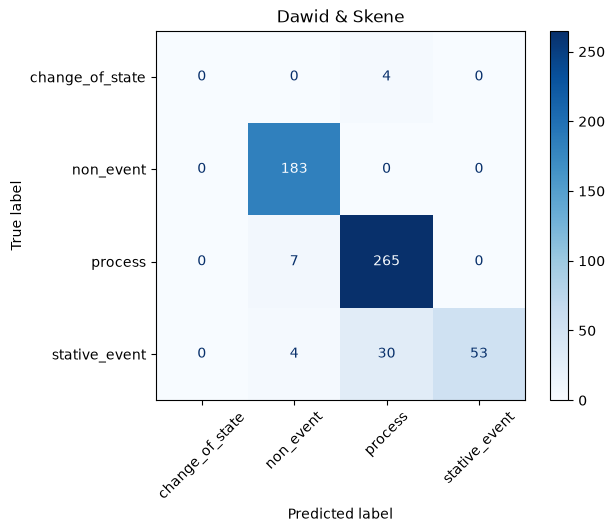

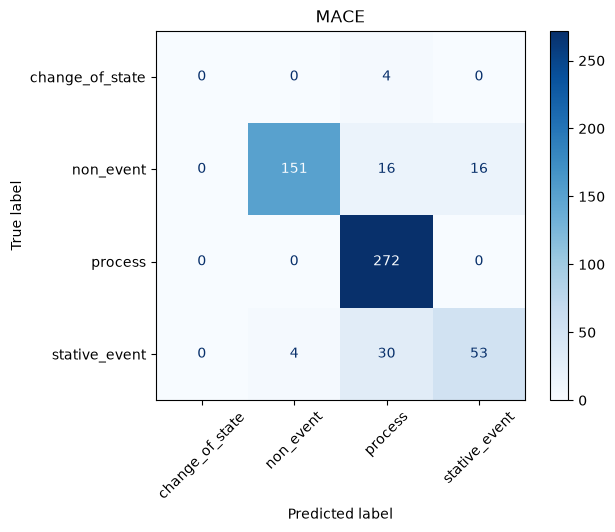

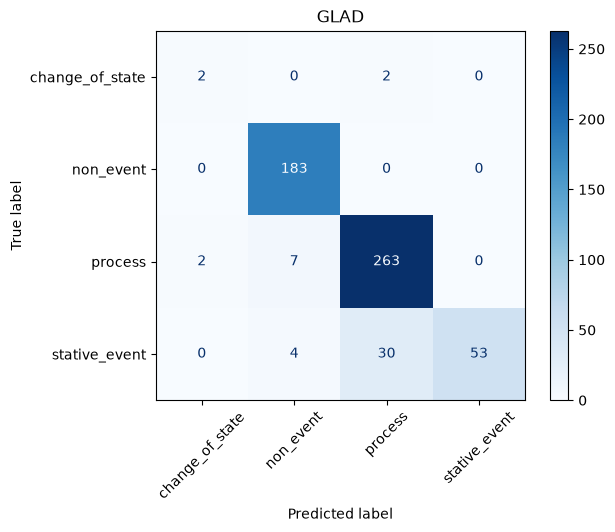

In [141]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for model_name, column in models.items():

    cm = confusion_matrix(
        df_erdbeben_gold["label"],
        df_erdbeben_gold[column],
        labels=sorted(df_erdbeben_gold["label"].dropna().unique())
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=sorted(df_erdbeben_gold["label"].dropna().unique())
    )

    disp.plot(cmap="Blues", xticks_rotation=45)
    plt.rcParams["font.family"] = "sans-serif"
    plt.title(model_name)
    plt.show()